# 14. Choose the counting threshold on the validation split

For each trained model (`*_best.pt` from notebooks 01-12) this notebook:
1. counts panels in the **validation** images at confidence thresholds 0.05-0.80,
2. selects the threshold with the lowest validation MAE (this is the fair way: the test set is not used to choose it),
3. reports the counting errors on the **test** images at that threshold, next to the default 0.25.

**Where do the weights come from?** Each of notebooks 01-12 saves `<dataset>_<model>_<BOX>_seed0_best.pt` in its `/kaggle/working/results/`. In this notebook use **Add Input -> Notebook Output Files** and add the 12 notebooks (only committed versions, 'Save Version -> Save & Run All', have output files), or upload the 12 `.pt` files as one Kaggle dataset. The search is recursive, so any folder layout works.

In [2]:
# Same library version for ALL 12 notebooks (the old runs used 8.4.163-8.4.175, which changed the head and the pretrained-weight transfer).
!pip install -q ultralytics==8.4.175

In [3]:
# ======================= EDIT ONLY THIS CELL =======================
FOLDER = "/kaggle/input"      # searched recursively for *_best.pt (the files saved by notebooks 01-12)
SRC = {
    "custom": "/kaggle/input/datasets/hamzazafar12/yolov11/MS Thesis Solar OBB.v2i.yolov11",
    "public": "/kaggle/input/datasets/hamzazafar12/publicdatasetyolov11/solar panel.v2i.yolov11",
}
THRESHOLDS = [round(0.05 * k, 2) for k in range(1, 17)]    # 0.05 ... 0.80
IMGSZ, IOU_NMS, MAX_DET = 640, 0.7, 1000
WORK = "/kaggle/working"
REFERENCE = 0.25                                           # default threshold, reported for comparison

### Helpers

In [4]:
import os, shutil, csv, json, math, statistics, time, platform
from pathlib import Path
import numpy as np
import yaml, torch
import ultralytics
from ultralytics import YOLO

EXTS = (".jpg", ".jpeg", ".png")
SPLIT_NAMES = {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}

def find_split(src, names):
    for n in names:
        if os.path.isdir(os.path.join(src, n, "images")):
            return n
    raise FileNotFoundError(f"No images folder found in {src} for {names}")

def poly_area(pts):
    s = 0.0
    for i in range(len(pts)):
        x1, y1 = pts[i]; x2, y2 = pts[(i + 1) % len(pts)]
        s += x1 * y2 - x2 * y1
    return abs(s) / 2.0

def clean_rows(label_path):
    """Read a YOLO label file and return clean polygon rows for class 0.
    - 4-value rows (x y w h) become rectangle polygons, so every row is a polygon
    - coordinates are clipped to [0, 1]
    - degenerate polygons (fewer than 3 points or ~zero area) are dropped
    """
    rows, st = [], dict(rows=0, box_rows=0, poly_rows=0, dropped=0, clipped=0)
    if not os.path.exists(label_path):
        return rows, st
    with open(label_path, encoding="utf-8") as f:
        for ln in f:
            parts = ln.split()
            if not parts:
                continue
            st["rows"] += 1
            try:
                vals = [float(v) for v in parts[1:]]
            except ValueError:
                st["dropped"] += 1; continue
            if len(vals) == 4:
                x, y, w, h = vals
                pts = [(x - w / 2, y - h / 2), (x + w / 2, y - h / 2), (x + w / 2, y + h / 2), (x - w / 2, y + h / 2)]
                st["box_rows"] += 1
            elif len(vals) >= 6 and len(vals) % 2 == 0:
                pts = list(zip(vals[0::2], vals[1::2]))
                st["poly_rows"] += 1
            else:
                st["dropped"] += 1; continue
            if any(px < 0 or px > 1 or py < 0 or py > 1 for px, py in pts):
                st["clipped"] += 1
            pts = [(min(max(px, 0.0), 1.0), min(max(py, 0.0), 1.0)) for px, py in pts]
            if poly_area(pts) < 1e-8:
                st["dropped"] += 1; continue
            rows.append("0 " + " ".join(f"{px:.6f} {py:.6f}" for px, py in pts))
    return rows, st

def prepare_dataset(src, dst):
    """Copy a Roboflow YOLO export to a writable folder with cleaned labels; return data.yaml path and a report."""
    if os.path.exists(dst):
        shutil.rmtree(dst)
    report = {}
    for split, names in SPLIT_NAMES.items():
        s = find_split(src, names)
        os.makedirs(f"{dst}/{split}/images"); os.makedirs(f"{dst}/{split}/labels")
        tot = dict(images=0, rows=0, box_rows=0, poly_rows=0, dropped=0, clipped=0, kept=0, max_per_image=0)
        for fn in sorted(os.listdir(os.path.join(src, s, "images"))):
            if not fn.lower().endswith(EXTS):
                continue
            shutil.copy2(os.path.join(src, s, "images", fn), f"{dst}/{split}/images/{fn}")
            rows, st = clean_rows(os.path.join(src, s, "labels", os.path.splitext(fn)[0] + ".txt"))
            with open(f"{dst}/{split}/labels/{os.path.splitext(fn)[0]}.txt", "w", encoding="utf-8") as f:
                f.write("\n".join(rows) + ("\n" if rows else ""))
            tot["images"] += 1; tot["kept"] += len(rows); tot["max_per_image"] = max(tot["max_per_image"], len(rows))
            for k in ("rows", "box_rows", "poly_rows", "dropped", "clipped"):
                tot[k] += st[k]
        report[split] = tot
    data_yaml = f"{dst}/data.yaml"
    with open(data_yaml, "w", encoding="utf-8") as f:
        yaml.safe_dump({"path": dst, "train": "train/images", "val": "val/images", "test": "test/images",
                        "nc": 1, "names": {0: "solar panel"}}, f)
    return data_yaml, report

def gt_count(label_file):
    if not os.path.exists(label_file):
        return 0
    with open(label_file, encoding="utf-8") as f:
        return sum(1 for ln in f if ln.strip())

def counting_metrics(gt, pred):
    n = len(gt)
    err = [p - g for g, p in zip(gt, pred)]
    ae = [abs(e) for e in err]
    rel = [abs(p - g) / g for g, p in zip(gt, pred) if g > 0]
    return {"MAE": sum(ae) / n,
            "RMSE": math.sqrt(sum(e * e for e in err) / n),
            "MAPE_pct": 100 * sum(rel) / len(rel) if rel else float("nan"),
            "bias": sum(err) / n,
            "median_AE": statistics.median(ae),
            "max_AE": max(ae)}

def f1_score(p, r):
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


### Select thresholds and evaluate

24 weight files found under /kaggle/input
custom yolo11n HBB -> threshold 0.45 | test MAE 3.364 (at 0.25: 6.418 )
custom yolo11n HBB -> threshold 0.4 | test MAE 4.109 (at 0.25: 6.655 )
custom yolo11n OBB -> threshold 0.5 | test MAE 3.164 (at 0.25: 5.655 )
custom yolo11n OBB -> threshold 0.4 | test MAE 4.127 (at 0.25: 6.036 )
custom yolo26n HBB -> threshold 0.4 | test MAE 3.691 (at 0.25: 5.473 )
custom yolo26n HBB -> threshold 0.35 | test MAE 3.509 (at 0.25: 4.418 )
custom yolo26n OBB -> threshold 0.45 | test MAE 3.4 (at 0.25: 5.364 )
custom yolo26n OBB -> threshold 0.4 | test MAE 3.964 (at 0.25: 6.291 )
custom yolov8n HBB -> threshold 0.4 | test MAE 4.055 (at 0.25: 6.382 )
custom yolov8n HBB -> threshold 0.4 | test MAE 3.545 (at 0.25: 5.8 )
custom yolov8n OBB -> threshold 0.4 | test MAE 3.836 (at 0.25: 5.582 )
custom yolov8n OBB -> threshold 0.35 | test MAE 3.927 (at 0.25: 4.982 )
public yolo11n HBB -> threshold 0.4 | test MAE 2.064 (at 0.25: 2.394 )
public yolo11n HBB -> threshold 0.3

n_seeds  threshold    MAE  MAE_sd    MAPE   RMSE   bias
dataset model   box                                                         
custom  yolo11n HBB        2      0.425  3.736   0.527   9.381  6.320  0.900
                OBB        2      0.450  3.646   0.681   9.147  6.221  0.718
        yolo26n HBB        2      0.375  3.600   0.129   9.456  5.852  0.710
                OBB        2      0.425  3.682   0.399   8.246  6.476  0.736
        yolov8n HBB        2      0.400  3.800   0.361   9.314  6.430  0.418
                OBB        2      0.375  3.882   0.064   9.636  6.772  1.409
public  yolo11n HBB        2      0.350  2.133   0.098  16.093  4.970 -0.189
                OBB        2      0.425  2.041   0.188  16.093  4.898 -1.032
        yolo26n HBB        2      0.375  1.757   0.085  13.298  4.485 -0.665
                OBB        2      0.300  1.904   0.097  14.991  4.501 -0.436
        yolov8n HBB        2      0.300  1.908   0.129  14.948  4.651 -0.230
                OBB        2      0.375  2.014   0.175  16.596  4.610 -0.491

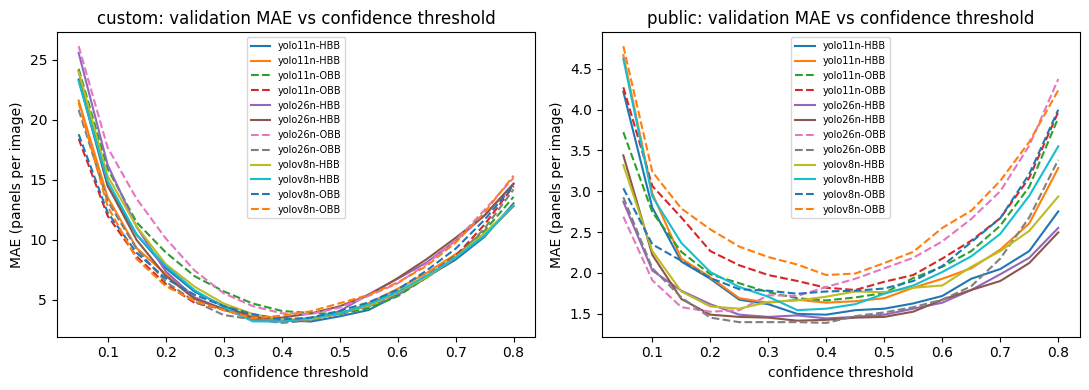

,dataset,model,box,seed,selected_threshold,val_MAE_at_selected,test_MAE,test_MAPE_pct,test_RMSE,test_bias,test_median_AE,test_MAE@0.25,test_bias@0.25
0,custom,yolo11n,HBB,seed0,0.45,3.182,3.364,8.185,5.928,0.382,2,6.418,5.436
1,custom,yolo11n,HBB,seed1,0.40,3.236,4.109,10.577,6.712,1.418,2,6.655,5.236
2,custom,yolo11n,OBB,seed0,0.50,3.818,3.164,7.765,5.437,-0.436,2,5.655,4.673
3,custom,yolo11n,OBB,seed1,0.40,3.291,4.127,10.530,7.005,1.873,2,6.036,5.200
4,custom,yolo26n,HBB,seed0,0.40,3.200,3.691,9.392,6.160,0.564,1,5.473,4.745
5,custom,yolo26n,HBB,seed1,0.35,3.509,3.509,9.521,5.545,0.855,2,4.418,3.291
6,custom,yolo26n,OBB,seed0,0.45,3.800,3.400,7.382,6.074,0.055,1,5.364,4.491
7,custom,yolo26n,OBB,seed1,0.40,3.073,3.964,9.110,6.878,1.418,2,6.291,5.164
8,custom,yolov8n,HBB,seed0,0.40,3.345,4.055,9.838,6.754,0.600,2,6.382,4.782
9,custom,yolov8n,HBB,seed1,0.40,3.182,3.545,8.789,6.107,0.236,2,5.800,4.127


In [6]:
import glob, matplotlib
import matplotlib.pyplot as plt

def collect(model, img_dir, lbl_dir, is_obb, low):
    out = []
    for im in sorted(f for f in os.listdir(img_dir) if f.lower().endswith(EXTS)):
        r = model.predict(os.path.join(img_dir, im), conf=low, iou=IOU_NMS, max_det=MAX_DET, imgsz=IMGSZ, verbose=False, device=0)[0]
        det = r.obb if is_obb else r.boxes
        confs = det.conf.cpu().numpy() if (det is not None and len(det)) else np.array([])
        out.append((im, gt_count(os.path.join(lbl_dir, os.path.splitext(im)[0] + ".txt")), confs))
    return out

def metrics_at(data, t):
    return counting_metrics([g for _, g, _ in data], [int((c > t).sum()) for _, _, c in data])

def select_threshold(val_curve):
    """Threshold with the lowest validation MAE; ties go to the smaller |bias|, then the lower threshold."""
    return min(val_curve, key=lambda t: (round(val_curve[t]["MAE"], 9), abs(val_curve[t]["bias"]), t))

prepared = {}
rows, curves, pi_rows = [], {}, []
WEIGHTS = sorted(glob.glob(f"{FOLDER}/**/*_best.pt", recursive=True))
_latest = {}
for _p in WEIGHTS:
    _k = os.path.basename(_p)
    if _k not in _latest or os.path.getmtime(_p) > os.path.getmtime(_latest[_k]): _latest[_k] = _p
if len(WEIGHTS) != len(_latest): print(f"{len(WEIGHTS) - len(_latest)} duplicate file name(s): keeping the most recently modified copy of each")
WEIGHTS = sorted(_latest.values())
print(len(WEIGHTS), "weight files found under", FOLDER)
assert WEIGHTS, (f"No *_best.pt files found under {FOLDER}.\n"
                 "Add the OUTPUT of notebooks 01-12 as inputs (Add Input -> Notebook Output Files) or upload the *_best.pt files as a Kaggle dataset, "
                 "then set FOLDER (the default '/kaggle/input' searches every input).")
for wf in WEIGHTS:
    ds, mo, bx, seed = os.path.basename(wf).replace("_best.pt", "").split("_")[:4]
    if ds not in prepared:
        prepared[ds] = prepare_dataset(SRC[ds], f"{WORK}/data_{ds}")[0]
    root = f"{WORK}/data_{ds}"
    model = YOLO(wf); is_obb = (bx == "OBB"); low = min(THRESHOLDS) - 1e-6
    val  = collect(model, f"{root}/val/images",  f"{root}/val/labels",  is_obb, low)
    test = collect(model, f"{root}/test/images", f"{root}/test/labels", is_obb, low)
    vc = {t: metrics_at(val, t) for t in THRESHOLDS}
    best_t = select_threshold(vc)
    tb, tr = metrics_at(test, best_t), metrics_at(test, REFERENCE)
    curves[(ds, mo, bx, seed)] = vc
    pi_rows += [(ds, mo, bx, seed, im, g, int((c > best_t).sum()), best_t) for im, g, c in test]
    rows.append({"dataset": ds, "model": mo, "box": bx, "seed": seed, "selected_threshold": best_t,
                 "val_MAE_at_selected": round(vc[best_t]["MAE"], 3),
                 "test_MAE": round(tb["MAE"], 3), "test_MAPE_pct": round(tb["MAPE_pct"], 3), "test_RMSE": round(tb["RMSE"], 3),
                 "test_bias": round(tb["bias"], 3), "test_median_AE": tb["median_AE"],
                 f"test_MAE@{REFERENCE}": round(tr["MAE"], 3), f"test_bias@{REFERENCE}": round(tr["bias"], 3)})
    print(ds, mo, bx, "-> threshold", best_t, "| test MAE", rows[-1]["test_MAE"], "(at 0.25:", rows[-1][f"test_MAE@{REFERENCE}"], ")")

with open(f"{WORK}/threshold_selection.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
with open(f"{WORK}/validation_threshold_curves.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["dataset", "model", "box", "seed", "threshold", "val_MAE", "val_MAPE_pct", "val_RMSE", "val_bias"])
    for k, vc in curves.items():
        for t, c in vc.items(): w.writerow([*k, t, round(c["MAE"], 3), round(c["MAPE_pct"], 3), round(c["RMSE"], 3), round(c["bias"], 3)])

import pandas as pd
pi = pd.DataFrame(pi_rows, columns=["dataset", "model", "box", "seed", "image", "gt_count", "pred_selected", "threshold"])
pi["error"] = pi["pred_selected"] - pi["gt_count"]; pi["abs_err"] = pi["error"].abs()
pi.to_csv(f"{WORK}/per_image_selected_threshold.csv", index=False)
summ = pd.DataFrame(rows)
agg = summ.groupby(["dataset", "model", "box"]).agg(n_seeds=("seed", "count"), threshold=("selected_threshold", "mean"),
        MAE=("test_MAE", "mean"), MAE_sd=("test_MAE", "std"), MAPE=("test_MAPE_pct", "mean"), RMSE=("test_RMSE", "mean"), bias=("test_bias", "mean")).round(3)
display(agg); agg.to_csv(f"{WORK}/counting_mean_sd.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, ds in zip(axes, ["custom", "public"]):
    for (d, mo, bx, seed), vc in curves.items():
        if d == ds: ax.plot(list(vc), [c["MAE"] for c in vc.values()], ("-" if bx == "HBB" else "--"), label=f"{mo}-{bx}")
    ax.set_title(f"{ds}: validation MAE vs confidence threshold"); ax.set_xlabel("confidence threshold"); ax.set_ylabel("MAE (panels per image)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{WORK}/threshold_curves.png", dpi=150); plt.show()
import pandas as pd
display(pd.DataFrame(rows))

### Paired OBB-vs-HBB comparison and density analysis

In [7]:
# Paired comparison OBB vs HBB: same test images, same seed, thresholds chosen on validation.
# Differences are averaged over the available seeds for each image; the interval is a bootstrap over test images.
rng = np.random.default_rng(0)
print("Mean absolute error difference, OBB minus HBB (negative = OBB better), 95% bootstrap interval over test images")
for (ds, mo), g in pi.groupby(["dataset", "model"]):
    if set(g["box"]) != {"HBB", "OBB"}: continue
    p = g.pivot_table(index=["image", "seed"], columns="box", values="abs_err").dropna()
    if p.empty: continue
    p["d"] = p["OBB"] - p["HBB"]
    per_image = p.groupby(level="image")["d"].mean()
    seeds = sorted(p.index.get_level_values("seed").unique())
    boots = [rng.choice(per_image.values, len(per_image)).mean() for _ in range(5000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    verdict = "interval excludes 0" if (lo > 0 or hi < 0) else "interval includes 0 (no clear difference)"
    print(f"  {ds:7s} {mo:8s}: {per_image.mean():+.2f}  [{lo:+.2f}, {hi:+.2f}]  seeds={seeds}  images={len(per_image)}  {verdict}")

pi["density_group"] = ""
for ds, d in pi.groupby("dataset"):
    q1, q2 = d.drop_duplicates("image")["gt_count"].quantile([1/3, 2/3])
    print(f"{ds}: low <= {q1:.0f} panels < medium <= {q2:.0f} panels < high")
    pi.loc[d.index, "density_group"] = np.where(d["gt_count"] <= q1, "low", np.where(d["gt_count"] <= q2, "medium", "high"))
pi["density_group"] = pd.Categorical(pi["density_group"], categories=["low", "medium", "high"], ordered=True)
res = pi.groupby(["dataset", "density_group", "model", "box"], observed=True)["abs_err"].mean().unstack("box").round(2)
display(res)      # mean absolute error by density group (averaged over the seeds available)

Mean absolute error difference, OBB minus HBB (negative = OBB better), 95% bootstrap interval over test images
  custom  yolo11n : -0.09  [-0.54, +0.36]  seeds=['seed0', 'seed1']  images=55  interval includes 0 (no clear difference)
  custom  yolo26n : +0.08  [-0.68, +0.95]  seeds=['seed0', 'seed1']  images=55  interval includes 0 (no clear difference)
  custom  yolov8n : +0.08  [-0.56, +0.76]  seeds=['seed0', 'seed1']  images=55  interval includes 0 (no clear difference)
  public  yolo11n : -0.09  [-0.44, +0.24]  seeds=['seed0', 'seed1']  images=109  interval includes 0 (no clear difference)
  public  yolo26n : +0.15  [-0.12, +0.42]  seeds=['seed0', 'seed1']  images=109  interval includes 0 (no clear difference)
  public  yolov8n : +0.11  [-0.17, +0.39]  seeds=['seed0', 'seed1']  images=109  interval includes 0 (no clear difference)
custom: low <= 24 panels < medium <= 48 panels < high
public: low <= 4 panels < medium <= 14 panels < high


box                             HBB   OBB
dataset density_group model              
custom  low           yolo11n  1.82  1.45
                      yolo26n  1.86  1.20
                      yolov8n  1.77  1.84
        medium        yolo11n  2.89  3.11
                      yolo26n  2.68  3.04
                      yolov8n  3.64  2.93
        high          yolo11n  6.58  6.58
                      yolo26n  6.29  7.03
                      yolov8n  6.26  6.95
public  low           yolo11n  0.32  0.37
                      yolo26n  0.26  0.36
                      yolov8n  0.29  0.40
        medium        yolo11n  1.34  1.02
                      yolo26n  0.94  0.95
                      yolov8n  1.32  1.06
        high          yolo11n  4.93  4.88
                      yolo26n  4.21  4.53
                      yolov8n  4.31  4.71